# 03: Published Variance Reproduction

## Objective

Recalculate the available NMC and pathwise MMC
variance results using the original verification
archive distributed by REPLICA.

In [1]:
from replica.studies.records.store import fetch

paths = fetch(
    "hopton2026unigram",
    verification=True,
)

for path in paths:
    print(path)

/home/hydrogen/PROJECTS/replica/.venv-replica/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/hydrogen/.cache/huggingface/hub/datasets--replicaverse--replica-study-bundles/snapshots/146205fafed1b5d6a17891301637a6d6dcf0c26b/bundles/hopton2026unigram/3f59ddf690451f3ff64a7122deaccac16c6026ad1402ee3e07d4f6058c1e122a.tar.gz
/home/hydrogen/.cache/huggingface/hub/datasets--replicaverse--replica-study-bundles/snapshots/146205fafed1b5d6a17891301637a6d6dcf0c26b/bundles/hopton2026unigram/321a00826389783d76ca8ea294b7290b81bf5a5e8482556decb017adc20639b7.tar.gz
/home/hydrogen/.cache/huggingface/hub/datasets--replicaverse--replica-study-bundles/snapshots/146205fafed1b5d6a17891301637a6d6dcf0c26b/bundles/hopton2026unigram/6efefa6769a902d770d322c409d3179e895d8789f72944c5112b2db1f1485077.tar.gz


In [2]:
from pathlib import Path

VARIANCE_ARCHIVE_NAME = (
    "321a00826389783d76ca8ea294b7290b81"
    "bf5a5e8482556decb017adc20639b7.tar.gz"
)

variance_archive = next(
    (
        Path(path)
        for path in paths
        if Path(path).name == VARIANCE_ARCHIVE_NAME
    ),
    None,
)

print("Variance archive:", variance_archive)

assert variance_archive is not None, (
    "Variance archive not found."
)

Variance archive: /home/hydrogen/.cache/huggingface/hub/datasets--replicaverse--replica-study-bundles/snapshots/146205fafed1b5d6a17891301637a6d6dcf0c26b/bundles/hopton2026unigram/321a00826389783d76ca8ea294b7290b81bf5a5e8482556decb017adc20639b7.tar.gz


In [3]:
import tarfile

with tarfile.open(variance_archive, "r:gz") as archive:
    for member in archive.getmembers():
        print(member.name)

MANIFEST.json
REPRODUCE.txt
author_code/__init__.py
author_code/caseviz_meco.js
author_code/hopton2026_r_reference.R
author_code/hopton2026_r_reference_selected.R
author_code/reference.py
author_code/variance.py
data/variance_boundaries.parquet
data/variance_samples.parquet
data/variance_units.parquet
provenance.json
replay_current_protocol.py
variance_three.tex


In [4]:
with tarfile.open(variance_archive, "r:gz") as archive:
    member = next(
        m for m in archive.getmembers()
        if Path(m.name).name == "REPRODUCE.txt"
    )

    instructions = archive.extractfile(member).read().decode("utf-8")

print(instructions)

Hopton variance input replay

This bundle recomputes the five NMC and five pathwise MMC table values.
The five expectation-equivalent (EE) values are retained reference values
only: their per-sample numerator inputs are not included.

Using Python 3.12, install the versions used to validate this replay:
  python -m pip install numpy==2.4.4 pandas==3.0.3 pyarrow==24.0.0

Run from this directory:
  OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python -B replay_current_protocol.py

The command checks file hashes, prints a two-estimator CSV, and exits with
an error if any of the ten values fails to match the recorded precision.
It uses seed 0 and 1,000 bootstrap resamples at J=100,200,300,400,500.
The archived Parquets remain unchanged. This replay subtracts one from each
stored boundary count in memory. The replay consumes
the omitted EE random draws to preserve the author's NMC, pathwise, EE order.

The author bootstrap converts nonpositive estimates to NaN before calculating
sample variance 

## Reproduction Protocol

The verification archive provides the necessary
inputs to recalculate ten published variance values.

Experimental configuration:

- Bootstrap resamples: 1,000
- Random seed: 0
- Sample sizes: 100, 200, 300, 400, 500
- Estimators: NMC and Pathwise MMC

In [5]:
from pathlib import Path
import tarfile

PROJECT_ROOT = Path.home() / "PROJECTS" / "unigram-surprisal-demo"

REPLAY_DIR = PROJECT_ROOT / "data" / "variance_replay"

REPLAY_DIR.mkdir(parents=True, exist_ok=True)

with tarfile.open(variance_archive, "r:gz") as archive:
    archive.extractall(
        path=REPLAY_DIR,
        filter="data",
    )

print("Archive extracted to:")
print(REPLAY_DIR)

print("\nExtracted files:")

for path in sorted(REPLAY_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(REPLAY_DIR))

Archive extracted to:
/home/hydrogen/PROJECTS/unigram-surprisal-demo/data/variance_replay

Extracted files:
MANIFEST.json
REPRODUCE.txt
author_code/__init__.py
author_code/caseviz_meco.js
author_code/hopton2026_r_reference.R
author_code/hopton2026_r_reference_selected.R
author_code/reference.py
author_code/variance.py
data/variance_boundaries.parquet
data/variance_samples.parquet
data/variance_units.parquet
provenance.json
replay_current_protocol.py
variance_three.tex


In [6]:
REPLAY_SCRIPT = REPLAY_DIR / "replay_current_protocol.py"

assert REPLAY_SCRIPT.is_file()

print(REPLAY_SCRIPT.read_text(encoding="utf-8"))

"""Replay the retained NMC and pathwise MMC variance inputs."""

import csv
import hashlib
import json
from pathlib import Path
import sys

import numpy as np

def main():
    root = Path(__file__).resolve().parent
    provenance = json.loads((root / "provenance.json").read_text())
    for entry in provenance["files"]:
        digest = hashlib.sha256((root / entry["path"]).read_bytes()).hexdigest()
        if digest != entry["sha256"]:
            raise ValueError(f"Checksum mismatch: {entry['path']}")

    from author_code import variance

    inputs = variance.load_inputs(root / "data")
    recipe = provenance["bootstrap"]
    rng = np.random.default_rng(recipe["seed"])
    writer = csv.writer(sys.stdout)
    writer.writerow(["J", "nmc", "mmc_pathwise"])
    matched = 0
    for expected in provenance["retained_table"]["rows"]:
        size = expected["J"]
        row = [size]
        for name, numerators, boundaries in (
            ("nmc", inputs.mc_counts, inputs.mc_boundaries),
  

In [7]:
import json

provenance = json.loads(
    (REPLAY_DIR / "provenance.json").read_text(
        encoding="utf-8"
    )
)

print(json.dumps(provenance, indent=2))

{
  "format_version": 1,
  "scope": "Replay of ten printed NMC/pathwise variance cells using the bundled archived inputs and code. Five EE reference values are retained only.",
  "files": [
    {
      "path": "data/variance_samples.parquet",
      "bytes": 4047502,
      "sha256": "aa938c16b2401f1081efd7eeac87d8b841dc8de00687b3a7e84def3afd41bcbc",
      "role": "archived per-sample numerator and count inputs"
    },
    {
      "path": "data/variance_boundaries.parquet",
      "bytes": 4735,
      "sha256": "1aa2d011707ddfde3f4241f67b6a7bb1e6184c017987b48a36a72b4954c5ed3c",
      "role": "archived per-sample denominator inputs"
    },
    {
      "path": "data/variance_units.parquet",
      "bytes": 10766,
      "sha256": "f5562755870e72d6123b645f82ef1f6789b100cad516d0c6227deb9e6257610d",
      "role": "archived corpus-unit mapping"
    },
    {
      "path": "author_code/variance.py",
      "bytes": 19335,
      "sha256": "897a3e27ecbf167abb9a05dba112b3d2f32ed7ebd89244afca29d516b38c5

## Isolated Replay Environment

The replay protocol specifies exact dependency
versions.

A dedicated virtual environment is created to
avoid modifying the existing REPLICA environment.

In [8]:
import sys
import subprocess

REPLAY_VENV = PROJECT_ROOT / ".venv-replay"
REPLAY_PYTHON = REPLAY_VENV / "bin" / "python"

assert sys.version_info[:2] == (3, 12), (
    "Python 3.12 is required for this replay."
)

if not REPLAY_PYTHON.exists():
    subprocess.run(
        [sys.executable, "-m", "venv", str(REPLAY_VENV)],
        check=True,
    )

print("Replay interpreter:", REPLAY_PYTHON)

subprocess.run(
    [str(REPLAY_PYTHON), "--version"],
    check=True,
)

Replay interpreter: /home/hydrogen/PROJECTS/unigram-surprisal-demo/.venv-replay/bin/python
Python 3.12.3


CompletedProcess(args=['/home/hydrogen/PROJECTS/unigram-surprisal-demo/.venv-replay/bin/python', '--version'], returncode=0)

In [9]:
installation = subprocess.run(
    [
        str(REPLAY_PYTHON),
        "-m",
        "pip",
        "install",
        "numpy==2.4.4",
        "pandas==3.0.3",
        "pyarrow==24.0.0",
    ],
    capture_output=True,
    text=True,
)

print(installation.stdout)

if installation.stderr:
    print(installation.stderr)

installation.check_returncode()

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/79.5 kB ? eta -:--:--
     ━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/79.5 kB 1.8 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━ 71.7/79.5 kB 901.9 kB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 898.1 kB/s eta 0:00:00
  Using cached python_dateutil-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.6 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/16.6 MB 4.3 MB/s eta 0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.2/16.6 MB 2.4 MB/s eta 0:00:07
   ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.2/16.6 MB 2.4 MB/s eta 0:00:07
   ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/16.6 MB 2.7 MB/s eta 0:00:07
   ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.4/16.6 MB 2.4 MB/s eta 0:00:07
   ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/16.6 MB 2.4 MB/s eta 0:00:07
   ━╸━━━━━━━━━

In [10]:
version_check = subprocess.run(
    [
        str(REPLAY_PYTHON),
        "-c",
        (
            "import numpy, pandas, pyarrow; "
            "print('NumPy:', numpy.__version__); "
            "print('Pandas:', pandas.__version__); "
            "print('PyArrow:', pyarrow.__version__)"
        ),
    ],
    capture_output=True,
    text=True,
    check=True,
)

print(version_check.stdout)

NumPy: 2.4.4
Pandas: 3.0.3
PyArrow: 24.0.0



## Execute the Original Replay Protocol

The original replay command is executed using
the archived script and the specified dependency
versions.

The script validates file hashes, performs the
bootstrap analysis and checks the recalculated
values against the recorded precision.

`OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 python -B replay_current_protocol.py`

In [11]:
import os
import time

env = os.environ.copy()

env["OPENBLAS_NUM_THREADS"] = "1"
env["OMP_NUM_THREADS"] = "1"

start = time.perf_counter()

replay = subprocess.run(
    [
        str(REPLAY_PYTHON),
        "-B",
        "replay_current_protocol.py",
    ],
    cwd=REPLAY_DIR,
    env=env,
    capture_output=True,
    text=True,
)

elapsed = time.perf_counter() - start

print("=== REPLAY OUTPUT ===\n")
print(replay.stdout)

if replay.stderr:
    print("=== STDERR / WARNINGS ===\n")
    print(replay.stderr)

print(f"\nExecution time: {elapsed:.2f} seconds")
print(f"Return code: {replay.returncode}")

replay.check_returncode()

=== REPLAY OUTPUT ===

J,nmc,mmc_pathwise
100,2.1808748138392264e-07,1.9853721825018674e-08
200,1.1084457010903327e-07,9.763632874196168e-09
300,8.0778394718380842e-08,6.4620711862035288e-09
400,6.6764038182391929e-08,4.5715094249113352e-09
500,5.1209275060576147e-08,3.8172958572583051e-09

=== STDERR / WARNINGS ===

/home/hydrogen/PROJECTS/unigram-surprisal-demo/data/variance_replay/author_code/variance.py:174: RuntimeWarning: Degrees of freedom <= 0 for slice.
  return np.nanvar(estimates, axis=0, ddof=1)
Matched 10/10 printed NMC/pathwise cells.
The five retained EE values were not recomputed.


Execution time: 1.09 seconds
Return code: 0


In [12]:
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_file = RESULTS_DIR / "variance_replay_output.txt"

output_file.write_text(
    replay.stdout,
    encoding="utf-8",
)

metadata = {
    "return_code": replay.returncode,
    "execution_time_seconds": elapsed,
    "bootstrap_resamples": 1000,
    "seed": 0,
    "sample_sizes": [100, 200, 300, 400, 500],
    "stderr": replay.stderr,
}

metadata_file = RESULTS_DIR / "variance_replay_metadata.json"

metadata_file.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Replay output saved to:", output_file)
print("Metadata saved to:", metadata_file)

Replay output saved to: /home/hydrogen/PROJECTS/unigram-surprisal-demo/results/variance_replay_output.txt
Metadata saved to: /home/hydrogen/PROJECTS/unigram-surprisal-demo/results/variance_replay_metadata.json


## Replay Results and Comparative Analysis

In [13]:
import pandas as pd
import numpy as np

from io import StringIO

assert replay.returncode == 0

variance_results = pd.read_csv(
    StringIO(replay.stdout)
)

variance_results["variance_ratio"] = (
    variance_results["nmc"]
    / variance_results["mmc_pathwise"]
)

variance_results["variance_reduction_pct"] = (
    1
    - variance_results["mmc_pathwise"]
    / variance_results["nmc"]
) * 100

variance_results

,J,nmc,mmc_pathwise,variance_ratio,variance_reduction_pct
0,100,2.180875e-07,1.985372e-08,10.984715,90.896441
1,200,1.108446e-07,9.763633e-09,11.352800,91.191600
2,300,8.077839e-08,6.462071e-09,12.500388,92.000248
3,400,6.676404e-08,4.571509e-09,14.604375,93.152737
4,500,5.120928e-08,3.817296e-09,13.415066,92.545694


In [14]:
reference = pd.DataFrame(
    provenance["retained_table"]["rows"]
)

comparison = variance_results.merge(
    reference,
    on="J",
    suffixes=("_computed", "_reference"),
)

for estimator in ["nmc", "mmc_pathwise"]:
    computed = comparison[f"{estimator}_computed"]
    expected = comparison[f"{estimator}_reference"]

    comparison[f"{estimator}_match"] = (
        computed.map(lambda x: format(x, ".3e"))
        == expected.astype(str)
    )

match_columns = [
    "nmc_match",
    "mmc_pathwise_match",
]

matched = int(comparison[match_columns].sum().sum())
total = comparison[match_columns].size

print(f"Matched reference values: {matched}/{total}")

assert matched == total == 10

comparison

Matched reference values: 10/10


,J,nmc_computed,mmc_pathwise_computed,variance_ratio,variance_reduction_pct,nmc_reference,mmc_pathwise_reference,mmc_expectation_equivalent,nmc_match,mmc_pathwise_match
0,100,2.180875e-07,1.985372e-08,10.984715,90.896441,2.181e-07,1.985e-08,1.770e-08,True,True
1,200,1.108446e-07,9.763633e-09,11.352800,91.191600,1.108e-07,9.764e-09,9.224e-09,True,True
2,300,8.077839e-08,6.462071e-09,12.500388,92.000248,8.078e-08,6.462e-09,6.298e-09,True,True
3,400,6.676404e-08,4.571509e-09,14.604375,93.152737,6.676e-08,4.572e-09,4.617e-09,True,True
4,500,5.120928e-08,3.817296e-09,13.415066,92.545694,5.121e-08,3.817e-09,3.804e-09,True,True


In [15]:
print(
    (REPLAY_DIR / "variance_three.tex")
    .read_text(encoding="utf-8")
)

\begin{tabular}{lccc}
\toprule
{$J$} & {NMC variance} & {MMC variance} & {MMC (Exp.\ Equiv.) variance} \\
\midrule
  100 & 2.181e-07 & 1.985e-08 & 1.770e-08 \\
  200 & 1.108e-07 & 9.764e-09 & 9.224e-09 \\
  300 & 8.078e-08 & 6.462e-09 & 6.298e-09 \\
  400 & 6.676e-08 & 4.572e-09 & 4.617e-09 \\
  500 & 5.121e-08 & 3.817e-09 & 3.804e-09 \\
\bottomrule
\end{tabular}



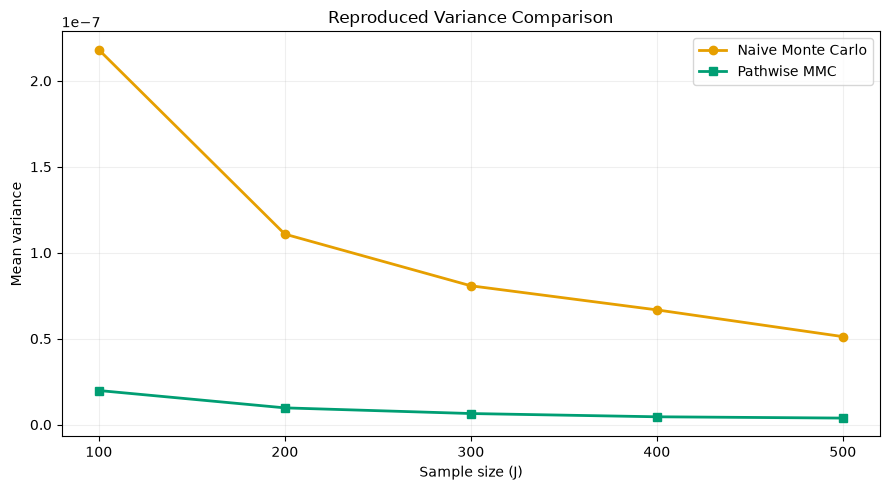

In [16]:
import matplotlib.pyplot as plt

plt.style.use("default")

NMC_COLOR = "#E69F00"
MMC_COLOR = "#009E73"

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    variance_results["J"],
    variance_results["nmc"],
    marker="o",
    linewidth=2,
    color=NMC_COLOR,
    label="Naive Monte Carlo",
)

ax.plot(
    variance_results["J"],
    variance_results["mmc_pathwise"],
    marker="s",
    linewidth=2,
    color=MMC_COLOR,
    label="Pathwise MMC",
)

ax.set_xlabel("Sample size (J)")
ax.set_ylabel("Mean variance")
ax.set_title("Reproduced Variance Comparison")
ax.set_xticks(variance_results["J"])
ax.ticklabel_format(
    axis="y",
    style="sci",
    scilimits=(0, 0),
)

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "variance_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

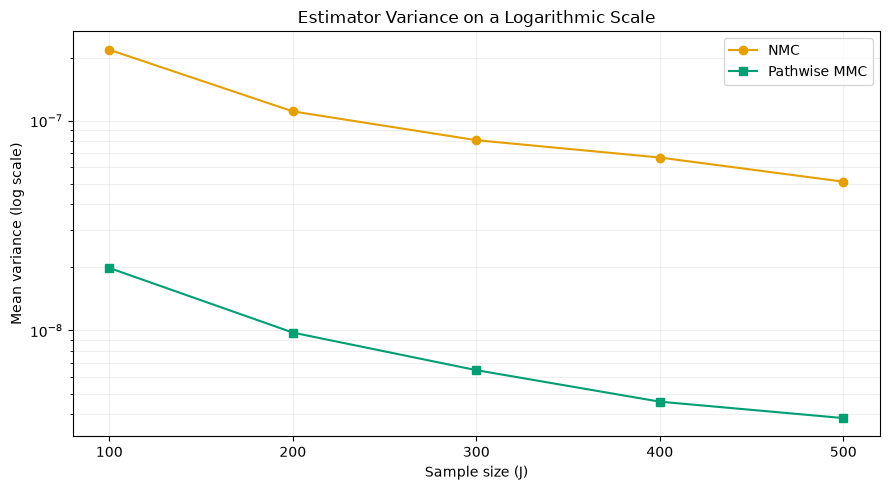

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    variance_results["J"],
    variance_results["nmc"],
    marker="o",
    color=NMC_COLOR,
    label="NMC",
)

ax.plot(
    variance_results["J"],
    variance_results["mmc_pathwise"],
    marker="s",
    color=MMC_COLOR,
    label="Pathwise MMC",
)

ax.set_yscale("log")
ax.set_xlabel("Sample size (J)")
ax.set_ylabel("Mean variance (log scale)")
ax.set_title("Estimator Variance on a Logarithmic Scale")
ax.set_xticks(variance_results["J"])

ax.legend()
ax.grid(alpha=0.2, which="both")

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "variance_log_scale.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

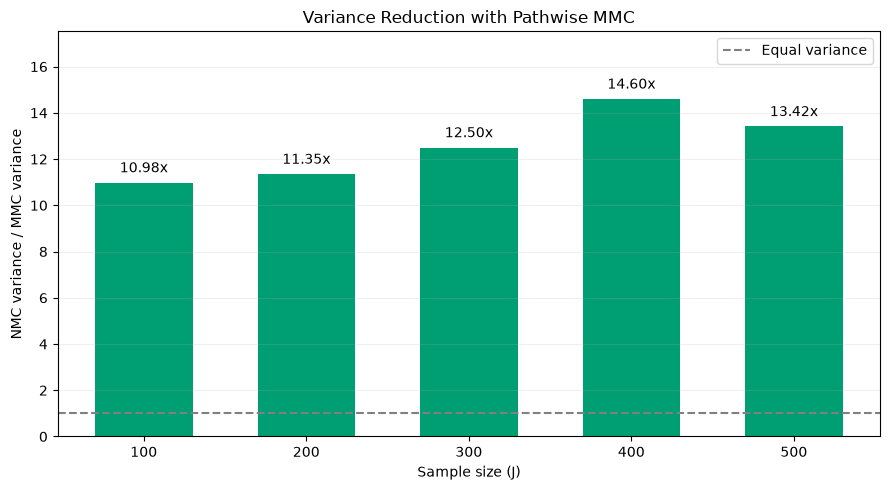

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    variance_results["J"].astype(str),
    variance_results["variance_ratio"],
    color=MMC_COLOR,
    width=0.6,
)

ax.bar_label(
    bars,
    labels=[
        f"{ratio:.2f}x"
        for ratio in variance_results["variance_ratio"]
    ],
    padding=5,
)

ax.axhline(
    1,
    linestyle="--",
    color="gray",
    label="Equal variance",
)

ax.set_xlabel("Sample size (J)")
ax.set_ylabel("NMC variance / MMC variance")
ax.set_title("Variance Reduction with Pathwise MMC")

ax.set_ylim(
    0,
    variance_results["variance_ratio"].max() * 1.2,
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    RESULTS_DIR / "variance_reduction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [19]:
variance_results.to_csv(
    RESULTS_DIR / "variance_reproduced.csv",
    index=False,
)

comparison.to_csv(
    RESULTS_DIR / "variance_reference_comparison.csv",
    index=False,
)

print("Minimum variance ratio:")
print(variance_results["variance_ratio"].min())

print("\nMaximum variance ratio:")
print(variance_results["variance_ratio"].max())

print("\nMean variance ratio:")
print(variance_results["variance_ratio"].mean())

print("\nExperiment completed successfully.")

Minimum variance ratio:
10.984715274347183

Maximum variance ratio:
14.604375049207478

Mean variance ratio:
12.571468724145506

Experiment completed successfully.
